# Machine Learning 2026 - Assignment 2

**Roll number:** 2024514  
**Topics:** K-Means, Gaussian Mixture Models (GMM), DBSCAN, TF-IDF, and Truncated SVD

This notebook follows the three practical sections in the assignment. The supplied CSV files should be in the notebook's working folder: `penguins.csv`, `airbnb_nyc.csv`, and `newsgroups.csv`.

## Setup and reproducibility

Import the libraries used in the experiments and set the required random seed. The figures and tables are displayed inline.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer

ROLL_NUMBER = 2024514
RANDOM_SEED = ROLL_NUMBER
np.random.seed(RANDOM_SEED)

required_files = ["penguins.csv", "airbnb_nyc.csv", "newsgroups.csv"]
possible_dirs = [".", "/mnt/data"]

def has_required_files(directory):
    try:
        for name in required_files:
            with open(f"{directory}/{name}", "rb"):
                pass
        return True
    except OSError:
        return False

DATA_DIR = next((directory for directory in possible_dirs if has_required_files(directory)), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Place penguins.csv, airbnb_nyc.csv, and newsgroups.csv in the notebook's working folder."
    )

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10})
print(f"Data directory: {DATA_DIR}")
print(f"Random seed: {RANDOM_SEED}")


Data directory: /mnt/data
Random seed: 2024514
Output directory: /mnt/data/a2_outputs


# 1. Palmer Penguins: K-Means and Gaussian Mixture Models

## 1.1 Exploratory data analysis and preprocessing

Use only bill length, bill depth, flipper length, and body mass as model inputs. The species column is reserved for the external evaluation subsection.

In [2]:
penguin_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins = pd.read_csv(f"{DATA_DIR}/penguins.csv", usecols=penguin_features)

# Convert the selected measurements to numeric values; blanks and invalid entries become missing values.
X_penguin_raw = penguins[penguin_features].apply(pd.to_numeric, errors="coerce")
penguin_missing = X_penguin_raw.isna().sum()

print(f"Number of observations: {len(penguins)}")
print(f"Number of selected numerical features: {len(penguin_features)}")
print("Missing values in selected features:")
display(penguin_missing.rename("missing_values").to_frame())

Number of observations: 344
Number of selected numerical features: 4
Missing values in selected features:


,missing_values
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2


In [3]:
# Impute each measurement with its median, then standardize each feature.
penguin_imputer = SimpleImputer(strategy="median")
X_penguin_imputed = penguin_imputer.fit_transform(X_penguin_raw)
penguin_scaler = StandardScaler()
X_penguin_scaled = penguin_scaler.fit_transform(X_penguin_imputed)

penguin_preprocessing_table = pd.DataFrame({
    "feature": penguin_features,
    "missing_before_imputation": penguin_missing.values,
    "median_used_for_imputation": penguin_imputer.statistics_,
    "mean_after_standardization": X_penguin_scaled.mean(axis=0),
    "std_after_standardization": X_penguin_scaled.std(axis=0),
})
print(f"Rows containing at least one missing selected measurement: {int(X_penguin_raw.isna().any(axis=1).sum())}")
display(penguin_preprocessing_table.round(4))

Rows containing at least one missing selected measurement: 2


,feature,missing_before_imputation,median_used_for_imputation,mean_after_standardization,std_after_standardization
0,bill_length_mm,2,44.45,-0.0,1.0
1,bill_depth_mm,2,17.30,0.0,1.0
2,flipper_length_mm,2,197.00,0.0,1.0
3,body_mass_g,2,4050.00,0.0,1.0


**Why standardize?** Distance-based clustering compares numerical differences between features. Body mass is measured in grams while bill measurements are in millimetres; without scaling, the numerically larger body-mass values could dominate Euclidean distances. Standardization puts the selected features on a comparable scale.

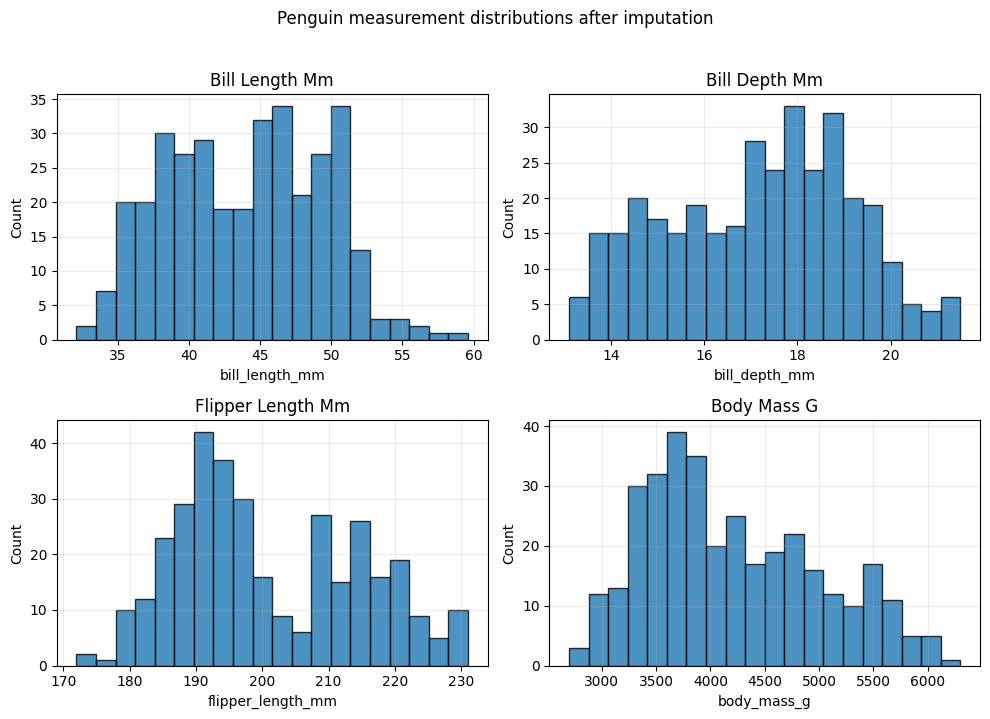

In [4]:
# Plot the distributions of the selected measurements after median imputation, in their original units.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.flat, penguin_features):
    ax.hist(X_penguin_imputed[:, penguin_features.index(feature)], bins=20, edgecolor="black", alpha=0.8)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
fig.suptitle("Penguin measurement distributions after imputation", y=1.02)
fig.tight_layout()
plt.show()

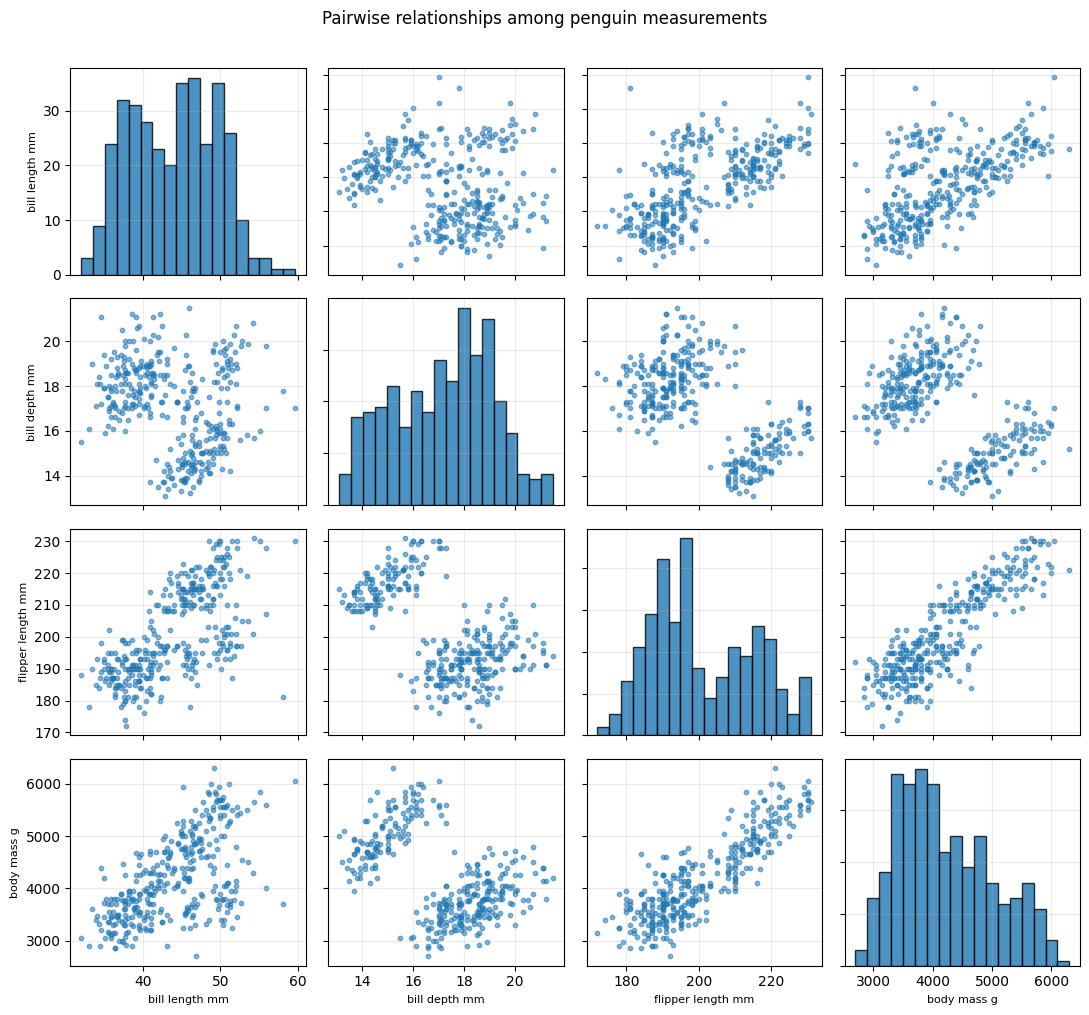

In [5]:
# Pairwise plots show the relationships among the four measurements before standardization.
fig, axes = plt.subplots(4, 4, figsize=(11, 10))
for i, feature_y in enumerate(penguin_features):
    for j, feature_x in enumerate(penguin_features):
        ax = axes[i, j]
        if i == j:
            ax.hist(X_penguin_imputed[:, j], bins=18, edgecolor="black", alpha=0.8)
        else:
            ax.scatter(X_penguin_imputed[:, j], X_penguin_imputed[:, i], s=10, alpha=0.55)
        if i == 3:
            ax.set_xlabel(feature_x.replace("_", " "), fontsize=8)
        else:
            ax.set_xticklabels([])
        if j == 0:
            ax.set_ylabel(feature_y.replace("_", " "), fontsize=8)
        else:
            ax.set_yticklabels([])
fig.suptitle("Pairwise relationships among penguin measurements", y=1.01)
fig.tight_layout()
plt.show()

## 1.2 K-Means clustering

Fit K-Means for each required value of K and use the average silhouette score as the unsupervised selection criterion. Species labels are not used to choose K.

,K,silhouette_score
0,2,0.5307
1,3,0.4443
2,4,0.3976
3,5,0.3759
4,6,0.3670


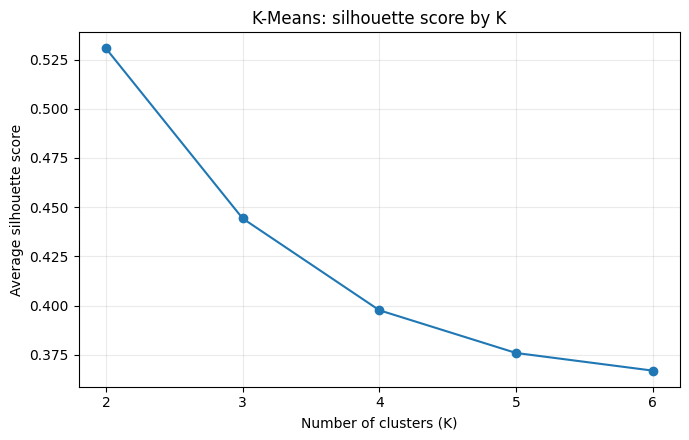

Selected K based on the highest silhouette score: 2


In [6]:
kmeans_silhouette_rows = []
kmeans_penguin_fits = {}
for k in [2, 3, 4, 5, 6]:
    model = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = model.fit_predict(X_penguin_scaled)
    score = silhouette_score(X_penguin_scaled, labels)
    kmeans_penguin_fits[k] = model
    kmeans_silhouette_rows.append({"K": k, "silhouette_score": score})

kmeans_silhouette_table = pd.DataFrame(kmeans_silhouette_rows)
display(kmeans_silhouette_table.round(4))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(kmeans_silhouette_table["K"], kmeans_silhouette_table["silhouette_score"], marker="o")
ax.set_xticks([2, 3, 4, 5, 6])
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Average silhouette score")
ax.set_title("K-Means: silhouette score by K")
fig.tight_layout()
plt.show()

selected_kmeans_k = int(kmeans_silhouette_table.loc[kmeans_silhouette_table["silhouette_score"].idxmax(), "K"])
selected_kmeans_penguin = kmeans_penguin_fits[selected_kmeans_k]
kmeans_penguin_labels = selected_kmeans_penguin.labels_
print(f"Selected K based on the highest silhouette score: {selected_kmeans_k}")

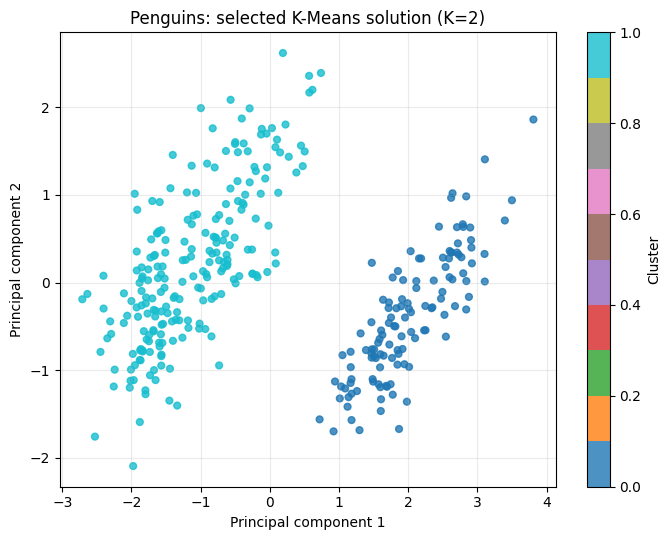

Cluster sizes:


,observations
cluster,
0,123
1,221


In [7]:
# Project the standardized measurements into two principal components for a cluster-assignment plot.
penguin_pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_penguin_pca = penguin_pca.fit_transform(X_penguin_scaled)
fig, ax = plt.subplots(figsize=(7, 5.5))
scatter = ax.scatter(X_penguin_pca[:, 0], X_penguin_pca[:, 1], c=kmeans_penguin_labels,
                     cmap="tab10", s=24, alpha=0.8)
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title(f"Penguins: selected K-Means solution (K={selected_kmeans_k})")
fig.colorbar(scatter, ax=ax, label="Cluster")
fig.tight_layout()
plt.show()

print("Cluster sizes:")
display(pd.Series(kmeans_penguin_labels).value_counts().sort_index().rename_axis("cluster").to_frame("observations"))

A K-Means centroid is the mean position of the observations assigned to a cluster. Minimizing the within-cluster sum of squared Euclidean distances makes observations close to their assigned centroid and therefore encourages compact clusters. This objective naturally favours roughly spherical/convex groups under the chosen distance scale, rather than strongly curved or irregular shapes.

## 1.3 Gaussian Mixture Models

Fit each combination of K in {2, 3, 4, 5, 6} and covariance type in {spherical, diag, tied, full}. Compare the fitted models using AIC and BIC.

In [8]:
gmm_penguin_fits = {}
gmm_result_rows = []
for covariance_type in ["spherical", "diag", "tied", "full"]:
    for k in [2, 3, 4, 5, 6]:
        model = GaussianMixture(
            n_components=k,
            covariance_type=covariance_type,
            random_state=RANDOM_SEED,
            n_init=1,
            max_iter=200,
            reg_covar=1e-6,
        )
        model.fit(X_penguin_scaled)
        gmm_penguin_fits[(k, covariance_type)] = model
        gmm_result_rows.append({
            "K": k,
            "covariance_type": covariance_type,
            "AIC": model.aic(X_penguin_scaled),
            "BIC": model.bic(X_penguin_scaled),
        })

gmm_information_criteria = pd.DataFrame(gmm_result_rows).sort_values(["BIC", "AIC"]).reset_index(drop=True)
display(gmm_information_criteria.round(2))
best_gmm_row = gmm_information_criteria.iloc[0]
selected_gmm_key = (int(best_gmm_row["K"]), str(best_gmm_row["covariance_type"]))
selected_gmm_penguin = gmm_penguin_fits[selected_gmm_key]
print(f"Selected GMM by lowest BIC: K={selected_gmm_key[0]}, covariance_type={selected_gmm_key[1]}")
print(f"Converged: {selected_gmm_penguin.converged_}; EM iterations used by the fitted model: {selected_gmm_penguin.n_iter_}")

,K,covariance_type,AIC,BIC
0,4,tied,2418.15,2529.53
1,3,tied,2452.95,2545.12
2,5,tied,2415.06,2545.64
3,6,tied,2427.48,2577.26
4,3,full,2410.24,2579.23
5,2,full,2498.13,2609.51
6,4,full,2412.12,2638.72
7,6,spherical,2538.99,2673.41
8,2,tied,2616.61,2689.58
9,5,full,2429.08,2713.29


Selected GMM by lowest BIC: K=4, covariance_type=tied
Converged: True; EM iterations used by the fitted model: 8


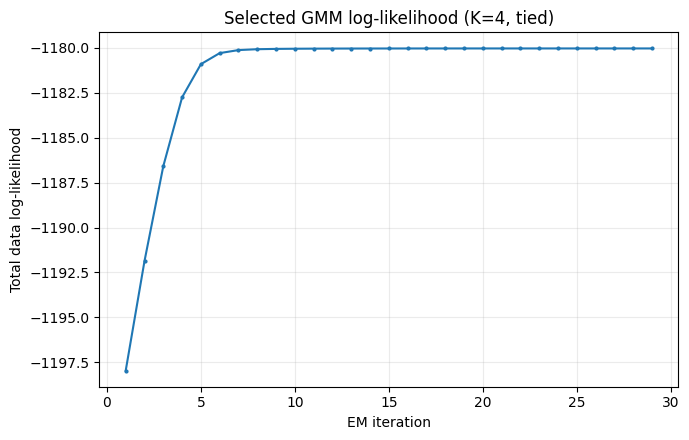

Trace iterations recorded: 29


In [9]:
# Track the selected GMM's data log-likelihood over one EM update per fit call, reusing parameters between calls.
trace_model = GaussianMixture(
    n_components=selected_gmm_key[0],
    covariance_type=selected_gmm_key[1],
    random_state=RANDOM_SEED,
    n_init=1,
    max_iter=1,
    tol=0,
    warm_start=True,
    reg_covar=1e-6,
)
log_likelihood_trace = []
for iteration in range(1, 101):
    trace_model.fit(X_penguin_scaled)
    log_likelihood_trace.append(float(trace_model.score(X_penguin_scaled) * len(X_penguin_scaled)))
    if iteration > 2 and abs(log_likelihood_trace[-1] - log_likelihood_trace[-2]) < 1e-5:
        break

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, len(log_likelihood_trace) + 1), log_likelihood_trace, marker=".", markersize=4)
ax.set_xlabel("EM iteration")
ax.set_ylabel("Total data log-likelihood")
ax.set_title(f"Selected GMM log-likelihood (K={selected_gmm_key[0]}, {selected_gmm_key[1]})")
fig.tight_layout()
plt.show()
print(f"Trace iterations recorded: {len(log_likelihood_trace)}")

In [10]:
# Show posterior component probabilities for five observations selected with the required seed.
rng = np.random.RandomState(RANDOM_SEED)
posterior_row_indices = np.sort(rng.choice(len(X_penguin_scaled), size=5, replace=False))
posterior_probabilities = selected_gmm_penguin.predict_proba(X_penguin_scaled[posterior_row_indices])
posterior_table = pd.DataFrame(
    posterior_probabilities,
    index=[int(i) for i in posterior_row_indices],
    columns=[f"P(component {j})" for j in range(selected_gmm_key[0])],
)
posterior_table.index.name = "observation_index"
display(posterior_table.round(4))

,P(component 0),P(component 1),P(component 2),P(component 3)
observation_index,,,,
179,1.0,0.0000,0.0000,0.0000
203,1.0,0.0000,0.0000,0.0000
213,1.0,0.0000,0.0000,0.0000
241,1.0,0.0000,0.0000,0.0000
279,0.0,0.0153,0.7895,0.1952


For a GMM, each mean vector is the centre of one Gaussian component. Its covariance matrix describes the component's spread and correlations among measurements. A full covariance matrix can represent elongated and rotated components because it includes cross-feature covariance terms; K-Means uses one centroid per cluster and squared Euclidean distance instead. K-Means makes a hard assignment, while a GMM provides soft posterior membership probabilities. A probability near 1 indicates strong membership in that component; similar probabilities across components indicate uncertainty or overlap.

## 1.4 Comparison with the true species

Species is used only here, after the unsupervised choices have been made. ARI and NMI compare the selected cluster assignments with the species labels while accounting for arbitrary cluster IDs.

In [11]:
# Ground-truth species labels are first used at this external-evaluation stage.
true_species = pd.read_csv(f"{DATA_DIR}/penguins.csv", usecols=["species"])["species"].astype(str).to_numpy()
gmm_penguin_labels = selected_gmm_penguin.predict(X_penguin_scaled)
penguin_external_metrics = pd.DataFrame([
    {
        "model": f"K-Means (K={selected_kmeans_k})",
        "ARI": adjusted_rand_score(true_species, kmeans_penguin_labels),
        "NMI": normalized_mutual_info_score(true_species, kmeans_penguin_labels),
    },
    {
        "model": f"GMM (K={selected_gmm_key[0]}, {selected_gmm_key[1]})",
        "ARI": adjusted_rand_score(true_species, gmm_penguin_labels),
        "NMI": normalized_mutual_info_score(true_species, gmm_penguin_labels),
    },
])
# Keep model names explicit in the comparison table.
penguin_external_metrics.loc[1, "model"] = f"GMM (K={selected_gmm_key[0]}, {selected_gmm_key[1]})"
display(penguin_external_metrics.round(4))

,model,ARI,NMI
0,K-Means (K=2),0.6456,0.7467
1,"GMM (K=4, tied)",0.7484,0.8168


The higher ARI/NMI indicates a closer overall match to the species partition, but the silhouette score need not select the same model: silhouette measures geometric separation in the feature space, while ARI/NMI compare the final partition with external labels. Species labels must not guide K selection because that would make the supposedly unsupervised selection use ground truth. A biological species need not form a perfectly separated mathematical cluster: measurements can overlap, individual variation exists, and the chosen features may not fully describe species identity.

# 2. Spatial Clustering with DBSCAN

Use only the latitude and longitude columns from the provided NYC listings file. The DBSCAN calculations below use great-circle (haversine) distances, reported in kilometres for easier interpretation.

In [12]:
spatial_df = pd.read_csv(f"{DATA_DIR}/airbnb_nyc.csv", usecols=["latitude", "longitude"])
spatial_df = spatial_df.apply(pd.to_numeric, errors="coerce")
spatial_missing_before_drop = spatial_df.isna().sum()
spatial_df = spatial_df.dropna(subset=["latitude", "longitude"]).reset_index(drop=True)
X_spatial = spatial_df[["latitude", "longitude"]].to_numpy()

print(f"Number of spatial observations loaded: {len(spatial_df)}")
print("Missing coordinate values before dropping incomplete coordinates:")
display(spatial_missing_before_drop.rename("missing_values").to_frame())

Number of spatial observations loaded: 30555
Missing coordinate values before dropping incomplete coordinates:


,missing_values
latitude,0
longitude,0


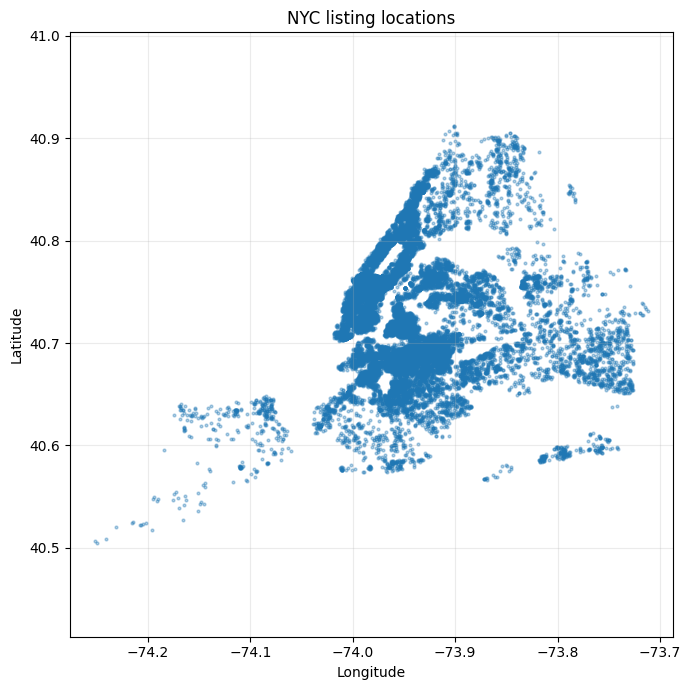

In [13]:
# Plot every available coordinate pair to inspect the spatial density and shape.
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X_spatial[:, 1], X_spatial[:, 0], s=4, alpha=0.35, rasterized=True)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("NYC listing locations")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()

## 2.2 K-Means on spatial data

Choose K=5 as a reasonable coarse partition after inspecting the coordinate scatter. This is a practical visualization choice rather than a claim that five is an objectively optimal number of clusters.

K-Means K: 5
Observations assigned: 30555 of 30555


,observations
cluster,
0,2155
1,11440
2,8298
3,2971
4,5691


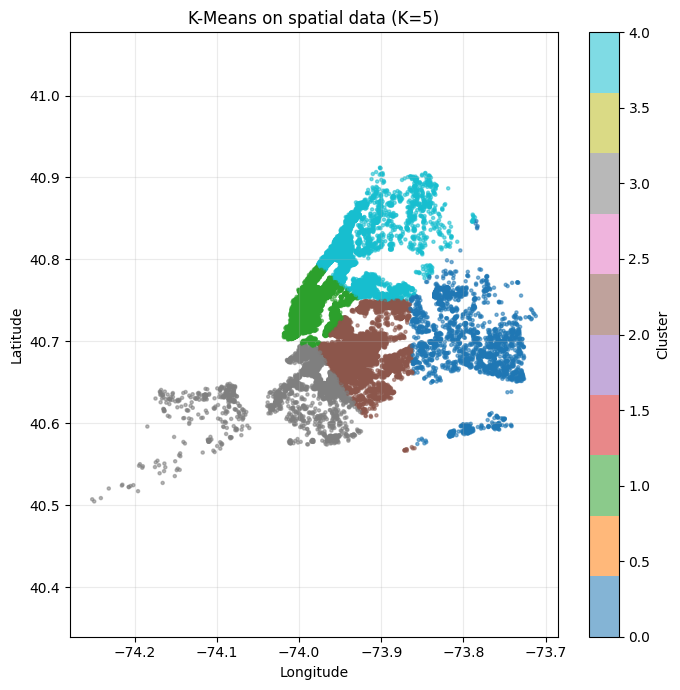

In [14]:
spatial_kmeans_k = 5
spatial_kmeans = KMeans(n_clusters=spatial_kmeans_k, random_state=RANDOM_SEED, n_init=10)
spatial_kmeans_labels = spatial_kmeans.fit_predict(X_spatial)
spatial_kmeans_sizes = pd.Series(spatial_kmeans_labels).value_counts().sort_index()
print(f"K-Means K: {spatial_kmeans_k}")
print(f"Observations assigned: {len(spatial_kmeans_labels)} of {len(X_spatial)}")
display(spatial_kmeans_sizes.rename_axis("cluster").to_frame("observations"))

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(X_spatial[:, 1], X_spatial[:, 0], c=spatial_kmeans_labels, cmap="tab10", s=5, alpha=0.55, rasterized=True)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"K-Means on spatial data (K={spatial_kmeans_k})")
ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(sc, ax=ax, label="Cluster")
fig.tight_layout()
plt.show()

K-Means assigns every observation to one of its K centroids, including isolated locations. As a result, isolated observations are forced into the nearest cluster, and the partition follows centroid-based regions rather than the detailed shape of dense spatial regions.

## 2.3 DBSCAN and parameter selection (bonus)

Use the distance to each point's 10th nearest neighbour to construct a k-distance plot. The plotted distances use the haversine metric and are converted to kilometres. Select `min_samples = 10` and start with `epsilon = 0.35 km`, near the bend in the sorted k-distance curve.

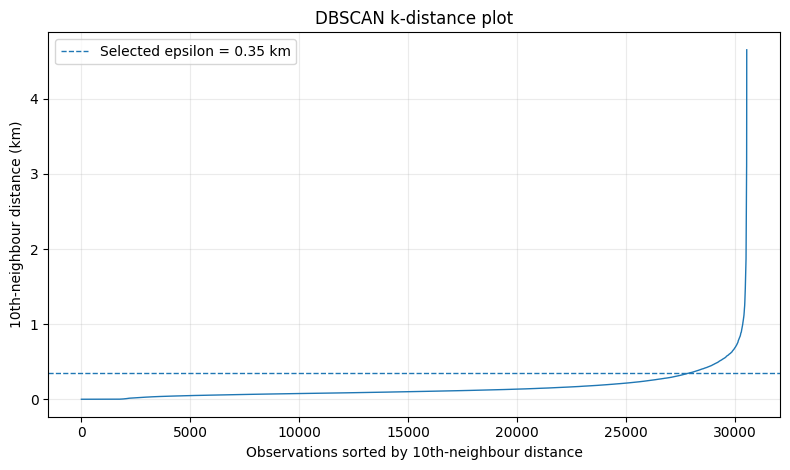

In [15]:
EARTH_RADIUS_KM = 6371.0088
spatial_radians = np.radians(X_spatial)
dbscan_min_samples = 10
nearest_neighbors = NearestNeighbors(
    n_neighbors=dbscan_min_samples,
    algorithm="ball_tree",
    metric="haversine",
    n_jobs=-1,
).fit(spatial_radians)
neighbor_distances, _ = nearest_neighbors.kneighbors(spatial_radians)
k_distance_km = np.sort(neighbor_distances[:, -1] * EARTH_RADIUS_KM)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(np.arange(1, len(k_distance_km) + 1), k_distance_km, linewidth=1)
ax.axhline(0.35, linestyle="--", linewidth=1, label="Selected epsilon = 0.35 km")
ax.set_xlabel("Observations sorted by 10th-neighbour distance")
ax.set_ylabel("10th-neighbour distance (km)")
ax.set_title("DBSCAN k-distance plot")
ax.legend()
fig.tight_layout()
plt.show()

selected_epsilon_km = 0.35

,experiment,epsilon_km,min_samples,number_of_clusters,noise_points,noise_percentage
0,Selected epsilon,0.35,10,77,1624,5.315


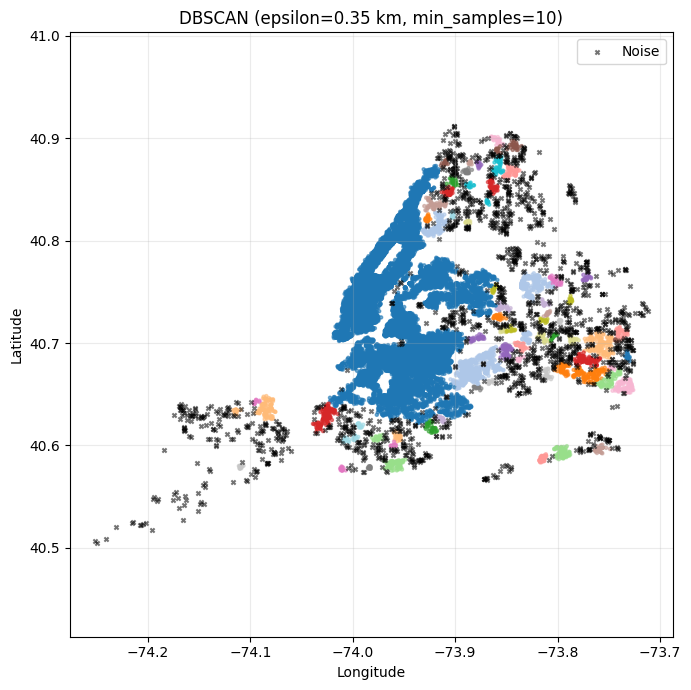

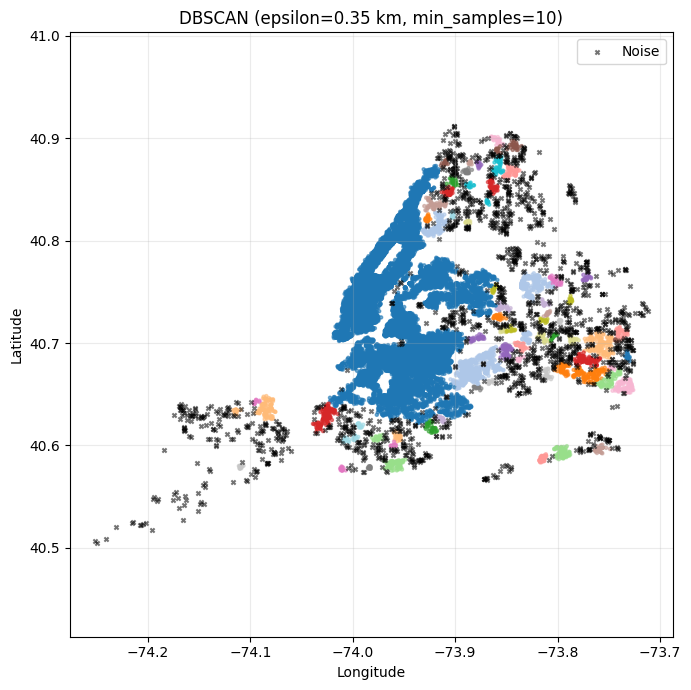

In [16]:
def fit_spatial_dbscan(epsilon_km, min_samples=dbscan_min_samples):
    model = DBSCAN(
        eps=epsilon_km / EARTH_RADIUS_KM,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree",
        n_jobs=-1,
    )
    return model.fit_predict(spatial_radians)

def summarize_dbscan(labels, epsilon_km):
    unique_clusters = sorted(set(labels) - {-1})
    noise_count = int(np.sum(labels == -1))
    return {
        "experiment": "Selected epsilon" if np.isclose(epsilon_km, selected_epsilon_km) else f"epsilon={epsilon_km:.2f} km",
        "epsilon_km": float(epsilon_km),
        "min_samples": int(dbscan_min_samples),
        "number_of_clusters": int(len(unique_clusters)),
        "noise_points": noise_count,
        "noise_percentage": float(100 * noise_count / len(labels)),
    }

def plot_spatial_dbscan(labels, epsilon_km):
    fig, ax = plt.subplots(figsize=(7, 7))
    noise_mask = labels == -1
    cluster_mask = ~noise_mask
    if np.any(cluster_mask):
        ax.scatter(X_spatial[cluster_mask, 1], X_spatial[cluster_mask, 0],
                   c=labels[cluster_mask], cmap="tab20", s=5, alpha=0.6, rasterized=True)
    if np.any(noise_mask):
        ax.scatter(X_spatial[noise_mask, 1], X_spatial[noise_mask, 0],
                   c="black", marker="x", s=9, alpha=0.55, label="Noise", rasterized=True)
        ax.legend(loc="best")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"DBSCAN (epsilon={epsilon_km:.2f} km, min_samples={dbscan_min_samples})")
    ax.set_aspect("equal", adjustable="datalim")
    fig.tight_layout()
    plt.show()
    return fig

selected_dbscan_labels = fit_spatial_dbscan(selected_epsilon_km)
selected_dbscan_summary = summarize_dbscan(selected_dbscan_labels, selected_epsilon_km)
display(pd.DataFrame([selected_dbscan_summary]).round(3))
plot_spatial_dbscan(selected_dbscan_labels, selected_epsilon_km)

DBSCAN forms a cluster from connected dense neighbourhoods and marks points that do not meet the core/border density conditions as noise. The epsilon radius comes from the bend in the k-distance plot; `min_samples` sets the neighbourhood density required for a core point.

## 2.4 Effect of epsilon

Run DBSCAN with one epsilon below the selected value, the selected value, and one above it. The smaller and larger settings here are 0.20 km and 0.50 km, respectively.

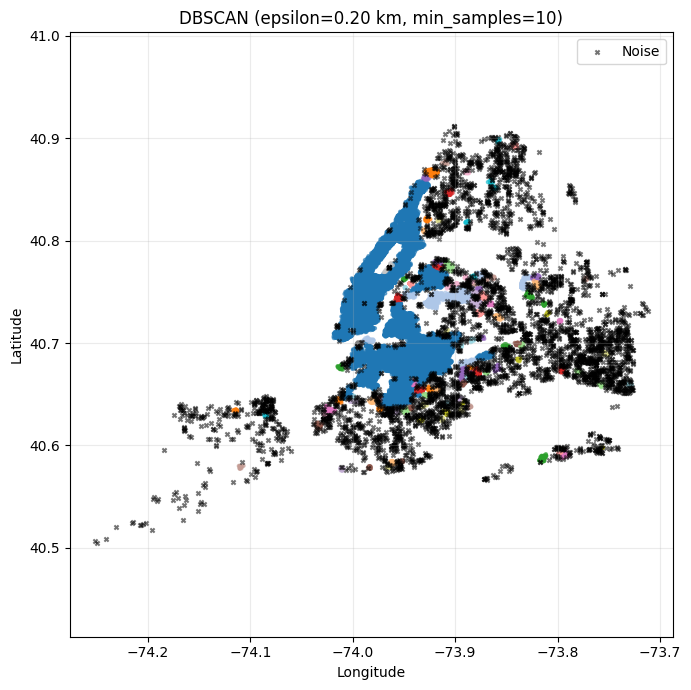

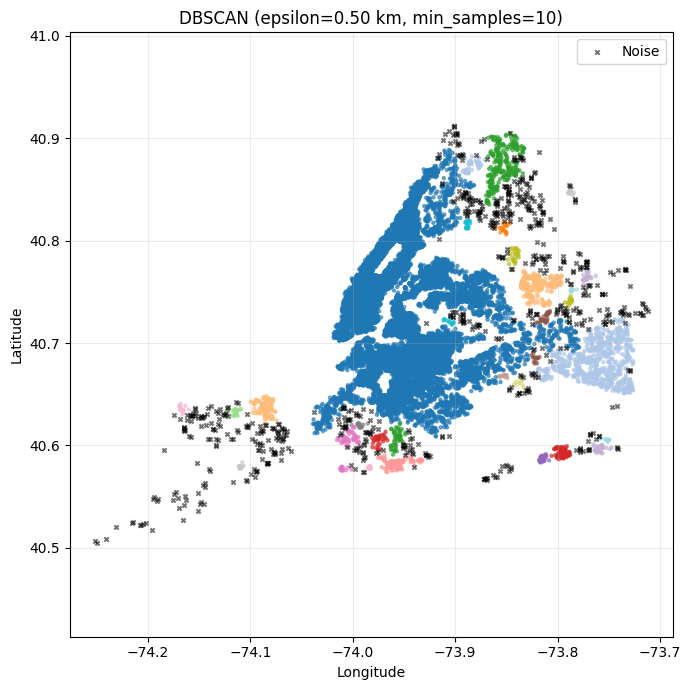

,experiment,epsilon_km,number_of_clusters,noise_points,noise_percentage
0,Small epsilon,0.20,128,4264,13.955
1,Selected epsilon,0.35,77,1624,5.315
2,Large epsilon,0.50,34,718,2.350


In [17]:
epsilon_experiments = [
    ("Small epsilon", 0.20),
    ("Selected epsilon", selected_epsilon_km),
    ("Large epsilon", 0.50),
]
epsilon_labels = {}
epsilon_rows = []
for experiment_name, epsilon_km in epsilon_experiments:
    labels = selected_dbscan_labels if np.isclose(epsilon_km, selected_epsilon_km) else fit_spatial_dbscan(epsilon_km)
    epsilon_labels[epsilon_km] = labels
    row = summarize_dbscan(labels, epsilon_km)
    row["experiment"] = experiment_name
    epsilon_rows.append(row)
    if not np.isclose(epsilon_km, selected_epsilon_km):
        plot_spatial_dbscan(labels, epsilon_km)

epsilon_comparison_table = pd.DataFrame(epsilon_rows)[
    ["experiment", "epsilon_km", "number_of_clusters", "noise_points", "noise_percentage"]
]
display(epsilon_comparison_table.round(3))

When epsilon is too small, many observations lack enough neighbours and are marked as noise, while dense areas can fragment into many small clusters. Increasing epsilon connects more points and merges clusters; if it is too large, distinct dense areas can be combined into a few large clusters and the number of noise points falls. DBSCAN can mark noise and recover irregularly shaped dense regions because it uses neighbourhood density rather than distance to a centroid. It does not require K in advance, but it is not parameter-free: epsilon and `min_samples` affect the result.

# 3. Clustering Text Documents

## 3.1 TF-IDF representation

Build the term-document representation from the document text only. The category column is reserved for the explicit external-evaluation step.

In [18]:
newsgroups = pd.read_csv(f"{DATA_DIR}/newsgroups.csv", usecols=["document_id", "text"])
documents = newsgroups["text"].fillna("").astype(str)

tfidf_vectorizer = TfidfVectorizer(max_features=8000, stop_words="english")
X_tfidf = tfidf_vectorizer.fit_transform(documents)
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()
tfidf_nonzero_entries = int(X_tfidf.nnz)
tfidf_total_entries = int(X_tfidf.shape[0] * X_tfidf.shape[1])
tfidf_sparsity = 1.0 - tfidf_nonzero_entries / tfidf_total_entries

text_representation_summary = pd.DataFrame([{
    "documents_N": X_tfidf.shape[0],
    "TF_IDF_features_D": X_tfidf.shape[1],
    "nonzero_entries": tfidf_nonzero_entries,
    "total_matrix_entries": tfidf_total_entries,
    "sparsity_percent": 100 * tfidf_sparsity,
}])
display(text_representation_summary.round(3))

,documents_N,TF_IDF_features_D,nonzero_entries,total_matrix_entries,sparsity_percent
0,2000,8000,114819,16000000,99.282


TF-IDF weights a term by how important it is in a document relative to its frequency across the collection. The matrix is sparse because each document contains only a small fraction of the full vocabulary. This representation differs from the penguin data: text is represented by thousands of mostly-zero term features, rather than four dense continuous measurements.

## 3.2 K-Means on text

Fit K-Means with K=4 on the original TF-IDF matrix and list the ten terms with the largest centroid weights in each cluster.

In [19]:
text_kmeans = KMeans(n_clusters=4, random_state=RANDOM_SEED, n_init=10)
text_kmeans_labels = text_kmeans.fit_predict(X_tfidf)
text_cluster_terms = []
for cluster_id, centroid in enumerate(text_kmeans.cluster_centers_):
    top_indices = np.argsort(centroid)[::-1][:10]
    top_terms = [str(tfidf_feature_names[index]) for index in top_indices]
    text_cluster_terms.append({"cluster": cluster_id, "representative_terms": ", ".join(top_terms)})
text_cluster_terms_table = pd.DataFrame(text_cluster_terms)
display(text_cluster_terms_table)

,cluster,representative_terms
0,0,"thanks, graphics, mail, image, files, does, hi..."
1,1,"people, just, don, like, think, know, governme..."
2,2,"game, year, baseball, team, games, think, play..."
3,3,"space, nasa, moon, shuttle, orbit, earth, miss..."


The representative terms provide an informal topic description for each cluster. A cluster may still be useful if its terms form a coherent theme, even when the cluster does not reproduce every original newsgroup category exactly; clustering is based on textual similarity rather than the supplied category names.

## 3.3 Dimensionality reduction with Truncated SVD

Reduce the TF-IDF matrix to 50 dimensions, run K-Means again with K=4, and then compare both clusterings with the true categories using ARI and NMI.

In [20]:
text_svd = TruncatedSVD(n_components=50, random_state=RANDOM_SEED)
X_svd = text_svd.fit_transform(X_tfidf)
text_svd_kmeans = KMeans(n_clusters=4, random_state=RANDOM_SEED, n_init=10)
text_svd_labels = text_svd_kmeans.fit_predict(X_svd)
text_svd_explained_variance = float(text_svd.explained_variance_ratio_.sum())
print(f"Reduced matrix shape: {X_svd.shape}")
print(f"Sum of explained variance ratios for the 50 components: {text_svd_explained_variance:.4f}")

Reduced matrix shape: (2000, 50)
Sum of explained variance ratios for the 50 components: 0.1199


In [21]:
# Use category labels only for the assignment's external evaluation of the two K-Means results.
true_categories = pd.read_csv(f"{DATA_DIR}/newsgroups.csv", usecols=["category"])["category"].astype(str).to_numpy()
text_external_metrics = pd.DataFrame([
    {
        "representation": "Original TF-IDF",
        "ARI": adjusted_rand_score(true_categories, text_kmeans_labels),
        "NMI": normalized_mutual_info_score(true_categories, text_kmeans_labels),
    },
    {
        "representation": "50-dimensional Truncated SVD",
        "ARI": adjusted_rand_score(true_categories, text_svd_labels),
        "NMI": normalized_mutual_info_score(true_categories, text_svd_labels),
    },
])
display(text_external_metrics.round(4))

,representation,ARI,NMI
0,Original TF-IDF,0.3876,0.4958
1,50-dimensional Truncated SVD,0.2865,0.4498


Dimensionality reduction can help by concentrating broad co-occurrence structure into fewer dimensions and reducing the burden of working directly in a large sparse vocabulary. It can also degrade clustering if distinctions important to a particular document or term are lost when projecting to 50 dimensions. The ARI/NMI comparison shows whether the reduced representation helped on this dataset.

## 3.4 Another clustering model on the reduced text representation (bonus)

Fit a diagonal-covariance GMM to the 50-dimensional SVD representation. Compare it with K-Means on the same representation using silhouette scores and cluster sizes, without using category labels for model fitting or selection.

In [22]:
text_gmm = GaussianMixture(
    n_components=4,
    covariance_type="diag",
    random_state=RANDOM_SEED,
    n_init=1,
    max_iter=200,
    reg_covar=1e-5,
)
text_gmm.fit(X_svd)
text_gmm_labels = text_gmm.predict(X_svd)

text_kmeans_silhouette = silhouette_score(X_svd, text_svd_labels)
text_gmm_silhouette = silhouette_score(X_svd, text_gmm_labels)
text_bonus_comparison = pd.DataFrame([
    {
        "model": "K-Means on SVD (K=4)",
        "silhouette_score": text_kmeans_silhouette,
        "cluster_sizes": ", ".join(str(int(v)) for v in pd.Series(text_svd_labels).value_counts().sort_index().values),
    },
    {
        "model": "GMM diagonal covariance (K=4)",
        "silhouette_score": text_gmm_silhouette,
        "cluster_sizes": ", ".join(str(int(v)) for v in pd.Series(text_gmm_labels).value_counts().sort_index().values),
    },
])
display(text_bonus_comparison.round(4))
print(f"GMM converged: {text_gmm.converged_}; EM iterations: {text_gmm.n_iter_}")

,model,silhouette_score,cluster_sizes
0,K-Means on SVD (K=4),0.0746,"212, 310, 379, 1099"
1,GMM diagonal covariance (K=4),-0.0341,"232, 811, 350, 607"


GMM converged: True; EM iterations: 47


The GMM adds soft probabilistic component assignments and models each component with its own diagonal variance in the reduced space. The negative silhouette score and uneven cluster sizes indicate weaker geometric separation than K-Means for this run. A diagonal covariance model also omits cross-component covariances. High-dimensional text data can be difficult for either method because many features are weak or sparse; dimensionality reduction makes the calculation smaller but can discard topic-specific information. A method that works well on spatial data may not work equally well on text because distance and density behave differently in high-dimensional spaces.